In [17]:
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
class LinearRegressionModel(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x):
        return self.linear(x)

In [19]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [20]:
X = df.drop("Outcome", axis=1).values.copy()
y = df["Outcome"].values.copy()

In [21]:
model = LinearRegressionModel(8,1)

In [22]:
X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float().unsqueeze(1)

X = (X - X.mean(dim=0)) / X.std(dim=0)

In [23]:
loss_fn = nn.BCEWithLogitsLoss() # for classifications
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.001)

In [24]:
epochs = 8000
losses = []

In [25]:
for epoch in range(epochs):
    model.train()
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    losses.append(loss.item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"{epoch}/{epochs} - loss: {loss.item():.4f}")

0/8000 - loss: 0.7792
100/8000 - loss: 0.7597
200/8000 - loss: 0.7417
300/8000 - loss: 0.7251
400/8000 - loss: 0.7098
500/8000 - loss: 0.6958
600/8000 - loss: 0.6828
700/8000 - loss: 0.6709
800/8000 - loss: 0.6598
900/8000 - loss: 0.6497
1000/8000 - loss: 0.6403
1100/8000 - loss: 0.6316
1200/8000 - loss: 0.6235
1300/8000 - loss: 0.6160
1400/8000 - loss: 0.6090
1500/8000 - loss: 0.6025
1600/8000 - loss: 0.5965
1700/8000 - loss: 0.5909
1800/8000 - loss: 0.5856
1900/8000 - loss: 0.5806
2000/8000 - loss: 0.5760
2100/8000 - loss: 0.5717
2200/8000 - loss: 0.5676
2300/8000 - loss: 0.5637
2400/8000 - loss: 0.5601
2500/8000 - loss: 0.5567
2600/8000 - loss: 0.5534
2700/8000 - loss: 0.5504
2800/8000 - loss: 0.5475
2900/8000 - loss: 0.5447
3000/8000 - loss: 0.5421
3100/8000 - loss: 0.5396
3200/8000 - loss: 0.5373
3300/8000 - loss: 0.5350
3400/8000 - loss: 0.5329
3500/8000 - loss: 0.5309
3600/8000 - loss: 0.5289
3700/8000 - loss: 0.5271
3800/8000 - loss: 0.5253
3900/8000 - loss: 0.5236
4000/8000 - 

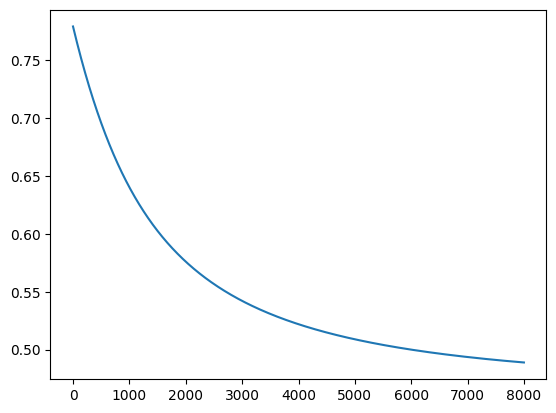

In [26]:
plt.plot(losses)

In [27]:
print(model.linear.bias)

Parameter containing:
tensor([-0.5585], requires_grad=True)
